nov 24

In [54]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import xarray as xr
import numpy as np
import pandas as pd
import pygmt

Gravitational attraction of an infinite horizontal slab with a density and thickness contrast:

\begin{equation*}
  \Delta g = 2\pi G \,\Delta\rho\ h
\end{equation*}

where $h$ is the slab thickness and $\Delta \rho$ is the density contrast. 

Now dicts in dicts for each layer
- dens in $kg/m^3$, thick in m

In [55]:
layers = {
    'water': {'thickness': 2000, 'density': 1030, 'color': 'blue'},
    'sediment': {'thickness': 200,  'density': 1880, 'color': 'tan'},
    'crust': {'thickness': 7000, 'density': 2750, 'color': 'sienna'},
    'mantle': {'thickness': 3000,'density': 3200, 'color': 'red'}}

First, define each layer's density contrast relative to a reference density $\rho_{ref}$, then sum:

\begin{equation*}
  \begin{split}
    \Delta g = 2\pi G \Big[ &(\rho_w - \rho_{ref})\,h_w + (\rho_s - \rho_{ref})\,h_s \\
    &+ (\rho_c - \rho_{ref})\,h_c + (\rho_m - \rho_{ref})\,h_m \Big]
  \end{split}
\end{equation*}

In [56]:
G = 6.674 * 1e-11  # grav constant
# dens_ref = 2670 # kg/m^3
dens_ref = layers['mantle']['density']

In [57]:
ins_dg = (
(layers['water']['density'] - dens_ref) * layers['water']['thickness'] 
+ (layers['sediment']['density'] - dens_ref) * layers['sediment']['thickness']
+ (layers['crust']['density'] - dens_ref) * layers['crust']['thickness']
+ (layers['mantle']['density'] - dens_ref) * layers['mantle']['thickness']
)

delta_g = 2 * np.pi * G * (ins_dg * 1e5) # multiplying by 1e5 to get mGal

print(f' Delta g: {delta_g} mGal')

print(type(delta_g))

 Delta g: -325.1560711508638 mGal
<class 'float'>


survey setup...

np.full_like creates a new array with the same shape as dx, filled entirely with delta_g

In [109]:
L = 100 # m, survey length
dL = 10 # m, survey spacing

dx = np.arange(0, L, dL)  # matrix of survey

dg = np.full_like(dx, delta_g, dtype=float)   # same anomaly at every station


In [110]:
print(dx)
print(dg)

[ 0 10 20 30 40 50 60 70 80 90]
[-325.15607115 -325.15607115 -325.15607115 -325.15607115 -325.15607115
 -325.15607115 -325.15607115 -325.15607115 -325.15607115 -325.15607115]


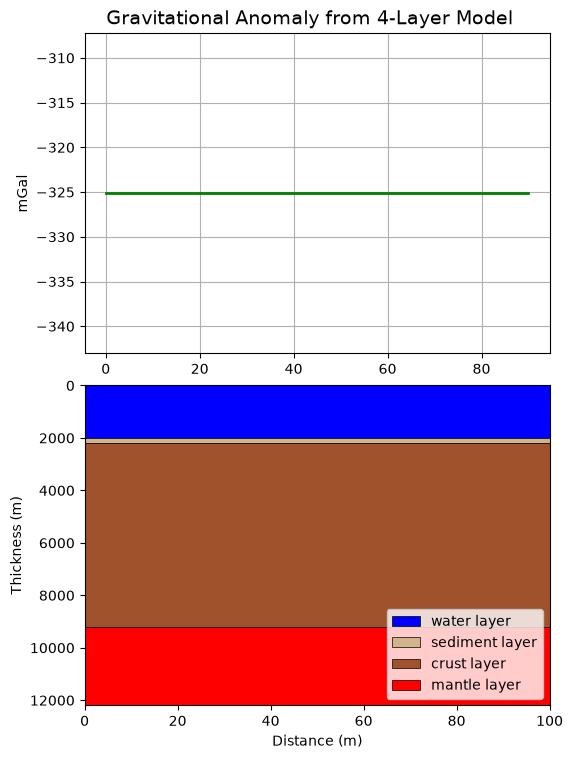

In [114]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(6, 8))

ax0.plot(dx, dg, color='green', label='Gravitational Anomaly', linewidth=2)

ax0.set_ylabel('mGal')
# ax0.set_xlabel('Distance (m)')

# defining poly geom
x0 = 0
x1 = L
bottom = 0


# name is key, l is value
for name, l in layers.items():
    # print(f'name: {name}\n l: {l}')
    n = l['thickness']
    rho_l = l['density']
    top = bottom + n

    #bl, br, tl, tr
    verts = [(x0, bottom), (x1, bottom),
        (x1, top), (x0, top)]

    poly = Polygon(verts, closed=True, facecolor=l['color'], edgecolor='black', linewidth=0.5,
                   label=f'{name} layer')
    
    ax1.add_patch(poly)

    bottom += n
    
ax1.set_xlim(0, x1)
ax1.set_ylim(0, bottom)
ax1.set_ylabel('Thickness (m)')
ax1.set_xlabel('Distance (m)')
ax1.invert_yaxis()

plt.legend(loc='lower right')
ax0.grid()

plt.suptitle('Gravitational Anomaly from 4-Layer Model', fontsize=14)
fig.subplots_adjust(top=0.95, hspace=0.1)


plt.show()

In [ ]:
# # defining poly geom
# x0 = 0
# x1 = L
# bottom = 0

# polys = {}

# # name is key, l is value
# for name, l in layers.items():
#     # print(f'name: {name}\n l: {l}')
#     n = l['thickness']
#     rho_l = l['density']
#     top = bottom + n

#     #bl, br, tl, tr
#     verts = [(x0, bottom), (x1, bottom),
#         (x1, top), (x0, top)]

#     poly = Polygon(verts, closed=True, facecolor=l['color'], edgecolor='black', linewidth=0.5)
#     ax1.add_patch(poly)

#     ax1.text(x0 + (x1 - x0) + 10, bottom + n/2, f't: {n} m\nρ: {rho_l} kg/m³', 
#              va='center', ha='left', fontsize=8)

#     # stores the polygon under its layer name in the dict 
#     polys[name] = poly

#     bottom += n

# # loc of sphere vs depth
# ax1.scatter(s1, z1, color='indigo', marker='o', s=r1, label='Buried Sphere 1', edgecolors='black')
# ax1.text(s1, z1 + r1 + 400, f'r: {r1} m\nρ: {rho1} kg/m³', fontsize=8, va='top', ha='center')


# ax1.set_xlim(0, x1)
# ax1.set_ylim(0, bottom)
# ax1.set_ylabel('Thickness (m)')
# ax1.set_xlabel('Distance (m)')
# ax1.invert_yaxis()

# leg = ax1.legend(loc='lower left', fontsize=10)
# for handle in leg.legend_handles:
#     handle.set_sizes([50])

# fig.suptitle('4 Layer Model with Gravity Anomaly', fontsize=12)
# fig.subplots_adjust(top=0.94, hspace=0.1)

# plt.savefig('..\\..\\figures\\4lay\\4laymod.png', dpi=400, bbox_inches='tight')
# plt.show()

nov 24: pad this. optimize sandwell and misfit and add term to obejctive func, also need to minimize surface and seis 